# Phase 5f — Main Results for the Paper (MuQ + SBERT)

Paper-ready results for the main system chosen after Phase 5e: **MuQ** (`MuQ-large-msd-iter`) audio and **SBERT**
(`all-mpnet-base-v2`) lyrics, with CLAP as a reference baseline. Same protocol as Phases 5b–5e: shared catalog of 2,075
multimodal tracks, shared splits, exact cosine top-K excluding the query, configurations chosen on each split's shared
validation set by quadrant P@10.

1. **Main results table** (replaces Table 3): P@5/10/20, nDCG@10 (σ = 0.10) and mean AV distance of the top 10, with
   bootstrap 95% CIs.
2. **Equivalence test** (TOST) for "music-pretrained audio ≈ lyrics": MuQ and MERT vs SBERT.
3. **Figures:** Precision@K curves (replaces Figure 4), per-quadrant P@10 (replaces Figure 6), and coherence vs
   retrieval quality (new; RQ3).

**Early fusion note.** Each modality is z-scored and L2-normalised before concatenation, so for unit vectors
cos([a; t], [a'; t']) = (a·a' + t·t') / 2: early fusion is *identical* to late fusion with α = 0.5. Section 1 checks this
numerically. The paper should present early fusion as this special case.

AV values and quadrants are evaluation targets only. `moods`, `genres` and `themes` are not read.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, t as t_dist
from sklearn.preprocessing import StandardScaler

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
SIGMA, KMAX, N_BOOT, SEED = 0.10, 20, 10_000, 42
ALPHAS  = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
rng = np.random.default_rng(SEED)

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
cat_sids  = lyrics_df['song_id'].tolist()
cat_pos   = {s: i for i, s in enumerate(cat_sids)}
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
a_row = [{s: i for i, s in enumerate(a_ids)}[s] for s in cat_sids]
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == cat_sids

muq  = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'),  mmap_mode='r')[a_row].astype(np.float64)
mert = np.load(os.path.join(ENC_DIR, 'audio_mert.npy'), mmap_mode='r')[a_row].astype(np.float64)
a_old = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet')).set_index('song_id').loc[cat_sids]
REPS = {'sbert': np.load(os.path.join(ENC_DIR, 'text_sbert_mpnet_trunc.npy')).astype(np.float64),
        'clap':  np.vstack(a_old['audio_clap'].values).astype(np.float64)}
for L in range(13):
    REPS[f'muq_L{L}'] = muq[:, L]; REPS[f'mert_L{L}'] = mert[:, L]
del muq, mert
FAMILY = lambda r: r.split('_L')[0]

lab  = merged.set_index('song_id').loc[cat_sids]
quad = lab['quadrant'].values
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
D_AV = np.linalg.norm(Y[:, None] - Y[None], axis=-1)

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
cat = set(cat_sids)
shared = {lbl: {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat)
                for sub in ['train', 'validate', 'test']} for sc, lbl in SCHEMES.items()}
print({lbl: {k: len(v) for k, v in d.items()} for lbl, d in shared.items()})

{'70/15/15': {'train': 1187, 'validate': 305, 'test': 302}, '40/30/30': {'train': 475, 'validate': 616, 'test': 617}}


## 1. Retrieval machinery and validation-based selection
Identical to Phase 5e: `raw` = L2-normalise, `z` = z-score each dimension over the catalog (no labels) then
L2-normalise; layer (MuQ/MERT), preprocessing and α are chosen on the shared validation set by quadrant P@10.

In [2]:
_unit = {}
def unit(rep, how):
    if (rep, how) not in _unit:
        X = REPS[rep]; X = StandardScaler().fit_transform(X) if how == 'z' else X
        _unit[(rep, how)] = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    return _unit[(rep, how)]

def score_matrix(cfg, rows):
    # cfg: ('single', (rep, how)) | ('late', (repA, howA), (repT, howT), alpha) | ('early', (repA, howA), (repT, howT))
    if cfg[0] == 'single':
        X = unit(*cfg[1]); return X[rows] @ X.T
    A, T = unit(*cfg[1]), unit(*cfg[2])
    if cfg[0] == 'late':
        return cfg[3] * (A[rows] @ A.T) + (1 - cfg[3]) * (T[rows] @ T.T)
    E = np.hstack([A, T]) / np.sqrt(2)                                     # unit-norm concatenation
    return E[rows] @ E.T

DISC = 1 / np.log2(np.arange(2, KMAX + 2))
def topk(S, k):
    # same selection as Phase 5e (argpartition at exactly k, then sort): duplicate tracks in MERGE give exact score
    # ties, and partitioning at a different k can break them differently, so each k is partitioned on its own
    top = np.argpartition(-S, k, 1)[:, :k]
    return np.take_along_axis(top, np.take_along_axis(S, top, 1).argsort(1)[:, ::-1], 1)

def evaluate(cfg, qs, exclude=None):
    # exclude: optional boolean (N, N) mask of catalog pairs that may not be retrieved for each other
    rows = np.array([cat_pos[s] for s in qs])
    S = score_matrix(cfg, rows); S[np.arange(len(rows)), rows] = -np.inf
    if exclude is not None:
        S[exclude[rows]] = -np.inf
    PK = np.column_stack([(quad[topk(S, k)] == quad[rows][:, None]).mean(1) for k in range(1, KMAX + 1)])
    top = topk(S, 10)
    d = np.take_along_axis(D_AV[rows], top, 1)
    Dq = D_AV[rows].copy(); Dq[np.arange(len(rows)), rows] = np.inf
    if exclude is not None:
        Dq[exclude[rows]] = np.inf
    g = np.exp(-d**2 / (2 * SIGMA**2)); gi = np.exp(-np.sort(Dq, 1)[:, :10]**2 / (2 * SIGMA**2))
    return {'P@K': PK, 'nDCG@10': (g * DISC[:10]).sum(1) / (gi * DISC[:10]).sum(1),
            'AVdist@10': d.mean(1), 'quadrant': quad[rows], 'song_id': np.array(qs)}

def best_single(lbl, family):
    reps = [r for r in REPS if FAMILY(r) == family]
    cands = [(r, h) for r in reps for h in ['raw', 'z']]
    return max(cands, key=lambda c: evaluate(('single', c), shared[lbl]['validate'])['P@K'][:, 9].mean())

def best_alpha(lbl, ca, ct):
    return max(ALPHAS, key=lambda al: evaluate(('late', ca, ct, al), shared[lbl]['validate'])['P@K'][:, 9].mean())

CFG = {}
for lbl in SCHEMES.values():
    c = {f: best_single(lbl, f) for f in ['muq', 'mert', 'sbert', 'clap']}
    a_muq, a_clap = best_alpha(lbl, c['muq'], c['sbert']), best_alpha(lbl, c['clap'], c['sbert'])
    CFG[lbl] = {
        'audio-only (MuQ)':         ('single', c['muq']),
        'lyrics-only (SBERT)':      ('single', c['sbert']),
        f'late fusion (α={a_muq})': ('late', c['muq'], c['sbert'], a_muq),
        'early fusion (≡ α=0.5)':   ('early', c['muq'], c['sbert']),
        'audio-only (CLAP)':        ('single', c['clap']),
        f'late fusion CLAP+SBERT (α={a_clap})': ('late', c['clap'], c['sbert'], a_clap),
        'audio-only (MERT)':        ('single', c['mert']),
    }
    print(lbl, {k: v[1:] for k, v in CFG[lbl].items()})

# early fusion == late fusion at alpha = 0.5 (unit-norm concatenation)
q = shared['70/15/15']['test'][:50]; rows = np.array([cat_pos[s] for s in q])
c = CFG['70/15/15']
assert np.allclose(score_matrix(('early', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1]), rows),
                   score_matrix(('late', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1], 0.5), rows))
print('early fusion == late fusion at α = 0.5: verified')

70/15/15 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.2)': (('clap', 'z'), ('sbert', 'z'), 0.2), 'audio-only (MERT)': (('mert_L7', 'z'),)}


40/30/30 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.3)': (('clap', 'z'), ('sbert', 'z'), 0.3), 'audio-only (MERT)': (('mert_L6', 'z'),)}
early fusion == late fusion at α = 0.5: verified


## 2. Main results table (test)
Bootstrap 95% CIs over test queries. Reference values from Phase 5e are asserted so this table cannot drift from it.

In [3]:
RES = {lbl: {name: evaluate(cfg, shared[lbl]['test']) for name, cfg in CFG[lbl].items()} for lbl in SCHEMES.values()}

def boot_ci(x, n=N_BOOT):
    idx = rng.integers(0, len(x), (n, len(x)))
    return np.percentile(x[idx].mean(1), [2.5, 97.5])

rows = []
for lbl, res in RES.items():
    for name, m in res.items():
        r = {'split': lbl, 'strategy': name, 'n': len(m['nDCG@10'])}
        for col, x in [('P@5', m['P@K'][:, 4]), ('P@10', m['P@K'][:, 9]), ('P@20', m['P@K'][:, 19]),
                       ('nDCG@10', m['nDCG@10']), ('AVdist@10', m['AVdist@10'])]:
            lo, hi = boot_ci(x); r.update({col: x.mean(), f'{col}_lo': lo, f'{col}_hi': hi})
        rows.append(r)
table = pd.DataFrame(rows)

ref = pd.read_csv(os.path.join(OUT_DIR, 'encoder_test_retrieval.csv'))
for lbl in SCHEMES.values():
    for fam, name in [('muq', 'audio-only (MuQ)'), ('sbert_mpnet_trunc', 'lyrics-only (SBERT)'), ('mert', 'audio-only (MERT)')]:
        r5e = ref[(ref.split == lbl) & (ref.family == fam)].iloc[0]
        r5f = table[(table.split == lbl) & (table.strategy == name)].iloc[0]
        assert abs(r5e.quad_precision - r5f['P@10']) < 1e-9 and abs(r5e.ndcg - r5f['nDCG@10']) < 1e-9, (lbl, fam)
print('Matches Phase 5e single-modality results.')

fmt = lambda r, c, d=3: f"{r[c]:.{d}f} [{r[c + '_lo']:.{d}f}, {r[c + '_hi']:.{d}f}]"
for lbl in SCHEMES.values():
    s = table[table.split == lbl]
    print(f'\n=== {lbl} shared test (n={s.n.iloc[0]}) ===')
    print(pd.DataFrame({c: s.apply(lambda r: fmt(r, c), axis=1).values for c in ['P@5', 'P@10', 'P@20', 'nDCG@10', 'AVdist@10']},
                       index=s.strategy.values).to_string())
table.to_csv(os.path.join(OUT_DIR, 'main_results_table.csv'), index=False)

Matches Phase 5e single-modality results.

=== 70/15/15 shared test (n=302) ===
                                                 P@5                  P@10                  P@20               nDCG@10             AVdist@10
audio-only (MuQ)                0.657 [0.621, 0.692]  0.625 [0.594, 0.656]  0.599 [0.571, 0.628]  0.440 [0.411, 0.469]  0.207 [0.195, 0.219]
lyrics-only (SBERT)             0.626 [0.588, 0.664]  0.605 [0.569, 0.640]  0.598 [0.565, 0.632]  0.427 [0.398, 0.455]  0.203 [0.191, 0.215]
late fusion (α=0.6)             0.713 [0.677, 0.748]  0.702 [0.669, 0.734]  0.678 [0.649, 0.707]  0.490 [0.461, 0.519]  0.178 [0.166, 0.191]
early fusion (≡ α=0.5)          0.710 [0.675, 0.746]  0.704 [0.673, 0.735]  0.680 [0.650, 0.710]  0.488 [0.460, 0.517]  0.178 [0.166, 0.190]
audio-only (CLAP)               0.387 [0.354, 0.419]  0.383 [0.355, 0.412]  0.378 [0.353, 0.404]  0.266 [0.244, 0.290]  0.283 [0.273, 0.294]
late fusion CLAP+SBERT (α=0.2)  0.622 [0.585, 0.658]  0.626 [0.592, 0.659]

### Paired tests for the main comparisons (test)
Wilcoxon signed-rank (Pratt) on per-query scores, Holm-corrected within each split × metric family.

In [4]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

trows = []
for lbl, res in RES.items():
    late = [k for k in res if k.startswith('late fusion (')][0]
    late_clap = [k for k in res if k.startswith('late fusion CLAP')][0]
    pairs = [(late, 'lyrics-only (SBERT)'), (late, 'audio-only (MuQ)'), ('early fusion (≡ α=0.5)', 'lyrics-only (SBERT)'),
             ('audio-only (MuQ)', 'lyrics-only (SBERT)'), ('audio-only (MuQ)', 'audio-only (CLAP)'), (late, late_clap)]
    for metric, get in [('P@10', lambda m: m['P@K'][:, 9]), ('nDCG@10', lambda m: m['nDCG@10'])]:
        block = []
        for a, b in pairs:
            d = get(res[a]) - get(res[b]); lo, hi = boot_ci(d)
            p = wilcoxon(get(res[a]), get(res[b]), zero_method='pratt').pvalue if (d != 0).any() else 1.0
            block.append({'split': lbl, 'metric': metric, 'comparison': f'{a} − {b}', 'diff': d.mean(), 'lo': lo, 'hi': hi, 'p': p})
        for r, ph in zip(block, holm([r['p'] for r in block])):
            r['p_holm'] = ph
        trows += block
tests = pd.DataFrame(trows)
print(tests.to_string(index=False, float_format=lambda x: f'{x:.3g}'))
tests.to_csv(os.path.join(OUT_DIR, 'main_results_tests.csv'), index=False)

   split  metric                                           comparison   diff        lo     hi        p   p_holm
70/15/15    P@10            late fusion (α=0.6) − lyrics-only (SBERT) 0.0974    0.0689  0.127 1.79e-09 5.38e-09
70/15/15    P@10               late fusion (α=0.6) − audio-only (MuQ) 0.0765    0.0536  0.099 9.91e-11 3.96e-10
70/15/15    P@10         early fusion (≡ α=0.5) − lyrics-only (SBERT) 0.0993    0.0732  0.126 4.76e-12 2.38e-11
70/15/15    P@10               audio-only (MuQ) − lyrics-only (SBERT) 0.0209   -0.0166 0.0583    0.657    0.657
70/15/15    P@10                 audio-only (MuQ) − audio-only (CLAP)  0.242     0.206  0.279 1.45e-25  8.7e-25
70/15/15    P@10 late fusion (α=0.6) − late fusion CLAP+SBERT (α=0.2) 0.0758     0.049  0.103 3.59e-07 7.18e-07
70/15/15 nDCG@10            late fusion (α=0.6) − lyrics-only (SBERT) 0.0634    0.0437 0.0832 5.22e-09 1.04e-08
70/15/15 nDCG@10               late fusion (α=0.6) − audio-only (MuQ) 0.0498    0.0351 0.0645  5.6e-10 2

### Sensitivity: duplicate tracks in MERGE
MERGE contains near-identical items: the same recording twice (audio cosine ≈ 1 in MuQ and MERT space) and pairs with
identical lyrics (mostly cover versions, lyric cosine ≈ 1). A duplicate's twin is an almost guaranteed same-quadrant hit,
which inflates retrieval, more for lyrics (more duplicate pairs) than for audio. Here every pair with cosine > 0.9999 in
MuQ, MERT or SBERT space is barred from retrieving each other, and the main metrics are recomputed.

In [5]:
def near_dup(X):
    X = X / np.linalg.norm(X, axis=1, keepdims=True); S = X @ X.T; np.fill_diagonal(S, -1)
    return S > 0.9999
DUP = near_dup(unit('muq_L6', 'z')) | near_dup(unit('mert_L7', 'z')) | near_dup(REPS['sbert'])
i, j = np.where(np.triu(DUP))
dups = pd.DataFrame({'song_id_a': np.array(cat_sids)[i], 'song_id_b': np.array(cat_sids)[j]})
dups = dups.join(lab[['artist', 'title', 'quadrant']].reset_index(drop=True).iloc[i].reset_index(drop=True).add_suffix('_a'))
dups = dups.join(lab[['artist', 'title', 'quadrant']].reset_index(drop=True).iloc[j].reset_index(drop=True).add_suffix('_b'))
dups['same_quadrant'] = dups.quadrant_a == dups.quadrant_b
print(f'{len(dups)} near-duplicate pairs ({DUP.any(1).sum()} tracks); same quadrant: {dups.same_quadrant.sum()}')
print(dups[['artist_a', 'title_a', 'artist_b', 'title_b', 'quadrant_a', 'quadrant_b']].to_string(index=False))
dups.to_csv(os.path.join(OUT_DIR, 'merge_near_duplicates.csv'), index=False)

srows = []
for lbl in SCHEMES.values():
    for name, cfg in CFG[lbl].items():
        a, b = RES[lbl][name], evaluate(cfg, shared[lbl]['test'], exclude=DUP)
        srows.append({'split': lbl, 'strategy': name, 'P@10': a['P@K'][:, 9].mean(), 'P@10_dedup': b['P@K'][:, 9].mean(),
                      'nDCG@10': a['nDCG@10'].mean(), 'nDCG@10_dedup': b['nDCG@10'].mean()})
sens = pd.DataFrame(srows)
sens['ΔP@10'] = sens['P@10_dedup'] - sens['P@10']; sens['ΔnDCG@10'] = sens['nDCG@10_dedup'] - sens['nDCG@10']
print(sens.round(4).to_string(index=False))
sens.to_csv(os.path.join(OUT_DIR, 'main_results_dedup_sensitivity.csv'), index=False)

14 near-duplicate pairs (28 tracks); same quadrant: 13
                      artist_a                      title_a           artist_b                           title_b quadrant_a quadrant_b
                          Enya        Journey of the Angels               Enya             Journey of the Angels         Q4         Q4
                        Prince                         Kiss             Prince                              Kiss         Q1         Q1
               Luther Vandross               Never Too Much    Luther Vandross                    Never Too Much         Q1         Q1
                   The Beatles              Twist and Shout The Isley Brothers                   Twist and Shout         Q1         Q1
                   Patsy Cline Just a Closer Walk With Thee      Willie Nelson      Just a Closer Walk With Thee         Q4         Q4
                 Hank Williams              I'm So Lonesome      Hank Williams      I'm So Lonesome, I Could Cry         Q3         Q3


   split                       strategy   P@10  P@10_dedup  nDCG@10  nDCG@10_dedup   ΔP@10  ΔnDCG@10
70/15/15               audio-only (MuQ) 0.6255      0.6258   0.4403         0.4404  0.0003    0.0001
70/15/15            lyrics-only (SBERT) 0.6046      0.6043   0.4267         0.4264 -0.0003   -0.0003
70/15/15            late fusion (α=0.6) 0.7020      0.7013   0.4901         0.4898 -0.0007   -0.0003
70/15/15         early fusion (≡ α=0.5) 0.7040      0.7033   0.4882         0.4880 -0.0007   -0.0003
70/15/15              audio-only (CLAP) 0.3834      0.3834   0.2664         0.2664  0.0000    0.0000
70/15/15 late fusion CLAP+SBERT (α=0.2) 0.6262      0.6255   0.4318         0.4317 -0.0007   -0.0001
70/15/15              audio-only (MERT) 0.6182      0.6185   0.4337         0.4340  0.0003    0.0003
40/30/30               audio-only (MuQ) 0.6353      0.6353   0.4530         0.4532  0.0000    0.0002
40/30/30            lyrics-only (SBERT) 0.6165      0.6165   0.4352         0.4347  0.0000 

## 3. Equivalence test: is music-pretrained audio as good as lyrics?
A non-significant difference is not evidence of equivalence. Two one-sided tests (TOST) on the paired per-query
differences: equivalence at α = 0.05 holds if the **90%** CI of the mean difference lies inside ±Δ.

Margins, fixed before looking at these tests: **Δ = 0.05 for P@10** and **Δ = 0.03 for nDCG@10**, about half of the
MuQ + SBERT fusion gain (+0.097 / +0.063), i.e. differences smaller than the effect the paper calls substantial.
The smallest margin at which equivalence would hold is also reported, so readers can apply their own.

In [6]:
MARGIN = {'P@10': 0.05, 'nDCG@10': 0.03}
erows = []
for lbl, res in RES.items():
    for audio in ['audio-only (MuQ)', 'audio-only (MERT)']:
        for metric, get in [('P@10', lambda m: m['P@K'][:, 9]), ('nDCG@10', lambda m: m['nDCG@10'])]:
            d = get(res[audio]) - get(res['lyrics-only (SBERT)']); n = len(d)
            idx = rng.integers(0, n, (N_BOOT, n)); bs = d[idx].mean(1)
            lo90, hi90 = np.percentile(bs, [5, 95])
            se = d.std(ddof=1) / np.sqrt(n); m = MARGIN[metric]
            p_tost = max(t_dist.sf((d.mean() + m) / se, n - 1), t_dist.cdf((d.mean() - m) / se, n - 1))
            erows.append({'split': lbl, 'audio': audio, 'metric': metric, 'mean_diff (audio − lyrics)': d.mean(),
                          'ci90_lo': lo90, 'ci90_hi': hi90, 'margin': m, 'equivalent (bootstrap)': (lo90 > -m) and (hi90 < m),
                          'p_TOST (paired t)': p_tost, 'smallest_equiv_margin': max(abs(lo90), abs(hi90))})
equiv = pd.DataFrame(erows)
print(equiv.to_string(index=False, float_format=lambda x: f'{x:.4g}'))
equiv.to_csv(os.path.join(OUT_DIR, 'equivalence_audio_vs_lyrics.csv'), index=False)

   split             audio  metric  mean_diff (audio − lyrics)   ci90_lo  ci90_hi  margin  equivalent (bootstrap)  p_TOST (paired t)  smallest_equiv_margin
70/15/15  audio-only (MuQ)    P@10                     0.02086  -0.01026  0.05199    0.05                   False            0.06332                0.05199
70/15/15  audio-only (MuQ) nDCG@10                     0.01358 -0.007608  0.03445    0.03                   False             0.1017                0.03445
70/15/15 audio-only (MERT)    P@10                     0.01358  -0.01887  0.04636    0.05                    True            0.03386                0.04636
70/15/15 audio-only (MERT) nDCG@10                    0.007011  -0.01502  0.02858    0.03                    True            0.04367                0.02858
40/30/30  audio-only (MuQ)    P@10                      0.0188 -0.002593  0.03987    0.05                    True           0.007917                0.03987
40/30/30  audio-only (MuQ) nDCG@10                     0.01782  

## 4. Figures
Palette (validated with the dataviz validator, light mode, adjacent pairs: all checks pass; aqua and yellow are below
3:1 contrast, so every line also carries a distinct marker and a direct end label): late fusion blue `#2a78d6`,
audio-only orange `#eb6834`, lyrics-only aqua `#1baf7a`, early fusion yellow `#eda100`; CLAP references in muted grey.

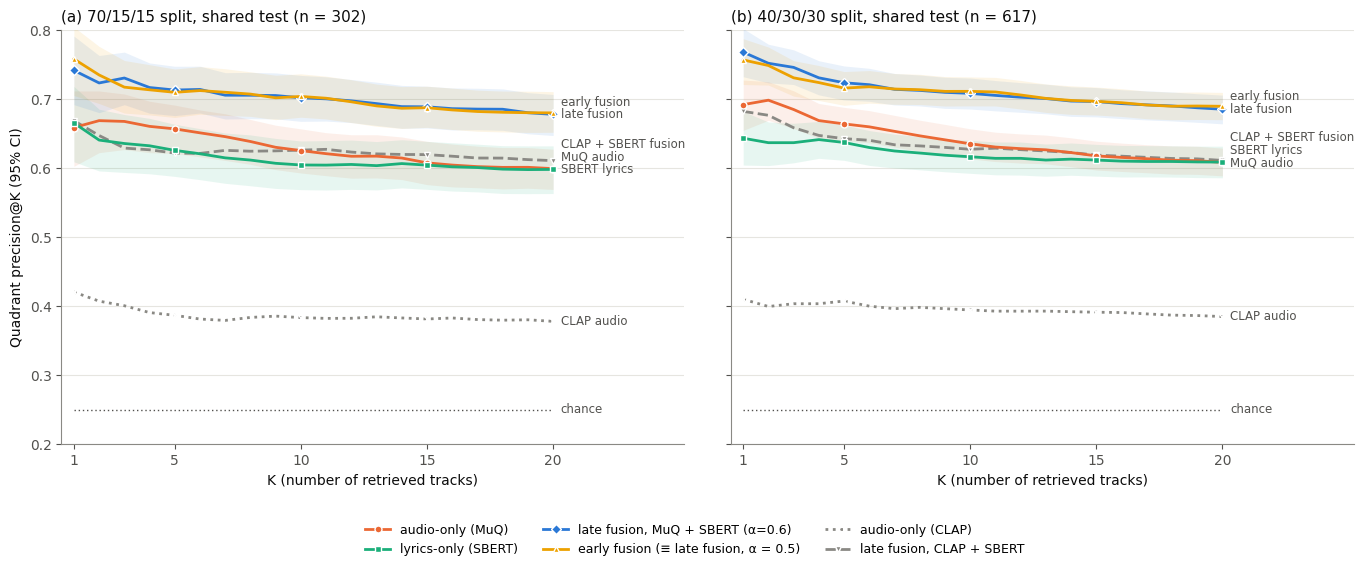

In [7]:
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e0'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.labelcolor': INK, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titlecolor': INK, 'legend.frameon': False})
def style(name):
    if name.startswith('late fusion CLAP'): return dict(color=MUTED, ls='--', marker='v', label='late fusion, CLAP + SBERT')
    if name.startswith('late fusion'):      return dict(color='#2a78d6', ls='-', marker='D', label=f'late fusion, MuQ + SBERT ({name.split("(")[1][:-1]})')
    return {'audio-only (MuQ)':       dict(color='#eb6834', ls='-', marker='o', label='audio-only (MuQ)'),
            'lyrics-only (SBERT)':    dict(color='#1baf7a', ls='-', marker='s', label='lyrics-only (SBERT)'),
            'early fusion (≡ α=0.5)': dict(color='#eda100', ls='-', marker='^', label='early fusion (≡ late fusion, α = 0.5)'),
            'audio-only (CLAP)':      dict(color=MUTED, ls=':', marker='x', label='audio-only (CLAP)'),
            'audio-only (MERT)':      None}[name]

# ── Figure: Precision@K curves, both splits (replaces Figure 4) ──────────────────────────────────────────────
K = np.arange(1, KMAX + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
for ax, lbl in zip(axes, SCHEMES.values()):
    res = RES[lbl]; ends = []
    for name, m in res.items():
        st = style(name)
        if st is None: continue
        P = m['P@K']; mean = P.mean(0)
        idx = rng.integers(0, len(P), (2000, len(P))); bs = P[idx].mean(1)
        lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
        main = st['color'] != MUTED
        if main:
            ax.fill_between(K, lo, hi, color=st['color'], alpha=0.10, lw=0)
        ax.plot(K, mean, color=st['color'], ls=st['ls'], lw=2, marker=st['marker'], ms=5 if main else 4,
                markevery=[0, 4, 9, 14, 19], mec='white', mew=1, label=st['label'], zorder=3 if main else 2)
        END = {'audio-only (MuQ)': 'MuQ audio', 'lyrics-only (SBERT)': 'SBERT lyrics', 'early fusion (≡ α=0.5)': 'early fusion',
               'audio-only (CLAP)': 'CLAP audio'}
        ends.append((mean[-1], END.get(name, 'CLAP + SBERT fusion' if 'CLAP' in name else 'late fusion'), st['color']))
    ax.plot([1, KMAX], [0.25, 0.25], color=INK2, lw=1, ls=(0, (1, 2)))
    ax.text(KMAX + 0.3, 0.25, 'chance', va='center', fontsize=8.5, color=INK2)
    # direct end labels, nudged apart so they never overlap
    ends.sort(); ys = []
    for y, _, _ in ends:
        ys.append(max(y, ys[-1] + 0.018) if ys else y)
    for (y, txt, c), yl in zip(ends, ys):
        ax.text(KMAX + 0.3, yl, txt, va='center', fontsize=8.5, color=INK2)
    ax.set_xlim(0.5, KMAX + 5.2); ax.set_xticks([1, 5, 10, 15, 20]); ax.set_ylim(0.2, 0.8)
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_xlabel('K (number of retrieved tracks)')
    ax.set_title(f'({"ab"[list(SCHEMES.values()).index(lbl)]}) {lbl} split, shared test (n = {len(res["audio-only (MuQ)"]["P@K"])})', loc='left')
axes[0].set_ylabel('Quadrant precision@K (95% CI)')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(os.path.join(OUT_DIR, 'main_precision_at_k.png'), dpi=200, bbox_inches='tight'); plt.show()

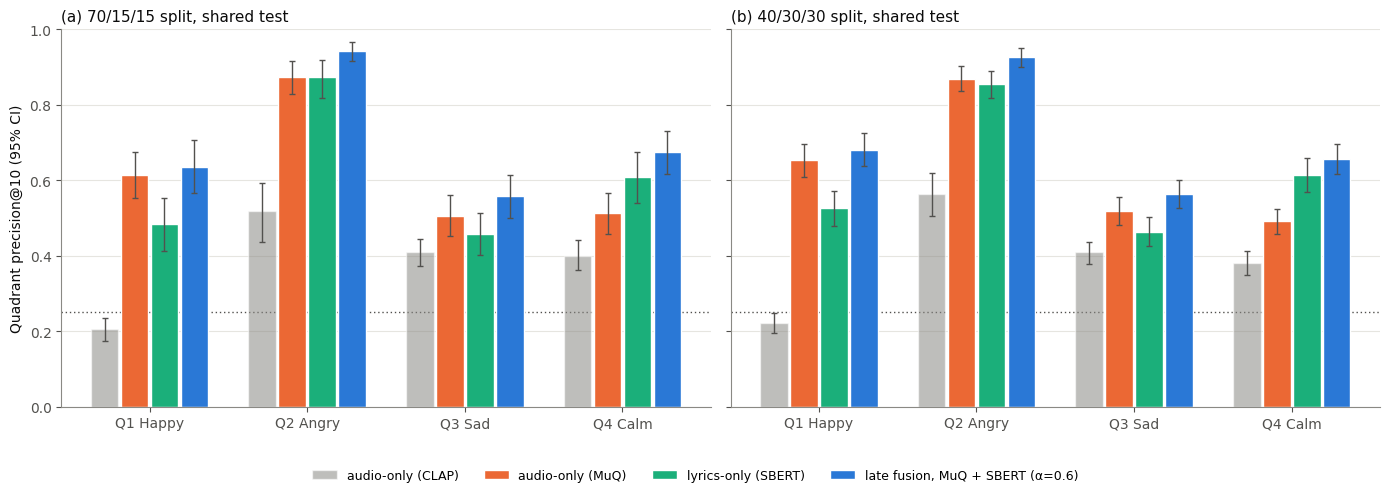

quadrant                         Q1     Q2     Q3     Q4
split    strategy                                       
40/30/30 audio-only (CLAP)    0.222  0.563  0.408  0.380
         audio-only (MuQ)     0.653  0.870  0.520  0.492
         late fusion (α=0.6)  0.681  0.927  0.563  0.656
         lyrics-only (SBERT)  0.526  0.854  0.463  0.614
70/15/15 audio-only (CLAP)    0.205  0.517  0.410  0.400
         audio-only (MuQ)     0.613  0.875  0.505  0.512
         late fusion (α=0.6)  0.636  0.943  0.557  0.676
         lyrics-only (SBERT)  0.483  0.873  0.457  0.609


In [8]:
# ── Figure: per-quadrant P@10 (replaces Figure 6) ────────────────────────────────────────────────────────────
SHOW = ['audio-only (MuQ)', 'lyrics-only (SBERT)', None, 'audio-only (CLAP)']       # None = late fusion (name varies)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
qrows = []
for ax, lbl in zip(axes, SCHEMES.values()):
    res = RES[lbl]
    names = [n if n else [k for k in res if k.startswith('late fusion (')][0] for n in SHOW]
    order = [names[3], names[0], names[1], names[2]]                                # CLAP, MuQ, SBERT, fusion
    w = 0.19; x = np.arange(4)
    for k, name in enumerate(order):
        st = style(name); m = res[name]; vals, err = [], [[], []]
        for q in QUADS:
            v = m['P@K'][m['quadrant'] == q, 9]; lo, hi = boot_ci(v, 2000)
            vals.append(v.mean()); err[0].append(v.mean() - lo); err[1].append(hi - v.mean())
            qrows.append({'split': lbl, 'strategy': name, 'quadrant': q, 'n': len(v), 'P@10': v.mean(), 'lo': lo, 'hi': hi})
        ax.bar(x + (k - 1.5) * w, vals, w * 0.92, color=st['color'], alpha=0.55 if st['color'] == MUTED else 1,
               edgecolor='white', lw=1, label=st['label'], zorder=2)
        ax.errorbar(x + (k - 1.5) * w, vals, yerr=err, fmt='none', ecolor=INK2, elinewidth=1, capsize=2, zorder=3)
    ax.axhline(0.25, color=INK2, lw=1, ls=(0, (1, 2)), zorder=1)
    ax.set_xticks(x); ax.set_xticklabels([f'{q} {QLAB[q]}' for q in QUADS])
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True); ax.set_ylim(0, 1)
    ax.set_title(f'({"ab"[list(SCHEMES.values()).index(lbl)]}) {lbl} split, shared test', loc='left')
axes[0].set_ylabel('Quadrant precision@10 (95% CI)')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(os.path.join(OUT_DIR, 'main_per_quadrant_p10.png'), dpi=200, bbox_inches='tight'); plt.show()
pd.DataFrame(qrows).to_csv(os.path.join(OUT_DIR, 'main_per_quadrant_p10.csv'), index=False)
print(pd.DataFrame(qrows).pivot_table(index=['split', 'strategy'], columns='quadrant', values='P@10').round(3).to_string())

### Coherence and retrieval quality (RQ3)
Coherence from Phase 4c (MuQ L7 and SBERT probes, cross-fitted). Queries: 70/15/15 shared test (n = 302), the
same queries as Phase 4c sections 5 and 10. Panel (c) reads `coherence_confound_check_muq.csv` (Phase 4c section 10).

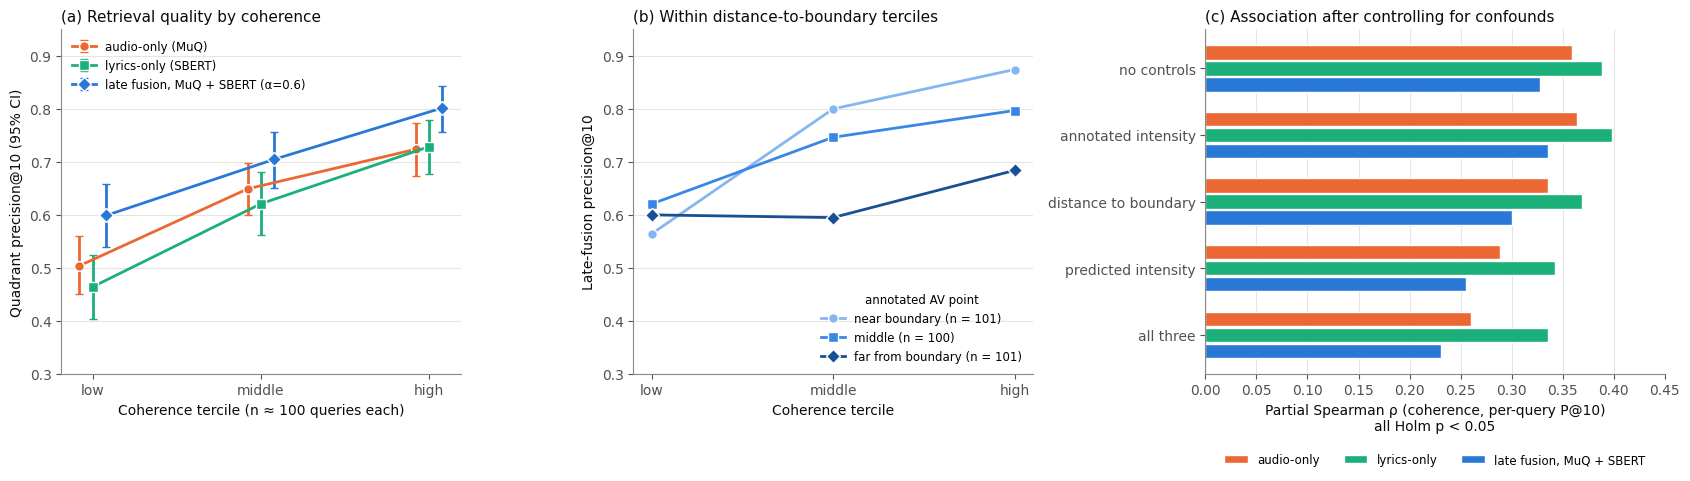

Saved: main_results_table.csv, main_results_tests.csv, equivalence_audio_vs_lyrics.csv, main_per_quadrant_p10.csv, main_precision_at_k.png, main_per_quadrant_p10.png, coherence_vs_retrieval.png


In [9]:
coh = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq.parquet')).set_index('song_id')
res = RES['70/15/15']; late = [k for k in res if k.startswith('late fusion (')][0]
qids = res['audio-only (MuQ)']['song_id']
cq = coh.loc[qids]
terc = pd.qcut(cq.coh_cos.values, 3, labels=['low', 'mid', 'high'])
bnd = np.minimum(np.abs(cq.arousal - 0.5), np.abs(cq.valence - 0.5)).values
bterc = pd.qcut(bnd, 3, labels=['near boundary', 'middle', 'far from boundary'])
conf = pd.read_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq.csv'))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1, 1, 1.15]})
# (a) P@10 by coherence tercile for each strategy
ax = axes[0]; xs = np.arange(3)
for k, name in enumerate(['audio-only (MuQ)', 'lyrics-only (SBERT)', late]):
    st = style(name); v = res[name]['P@K'][:, 9]
    means, lo, hi = [], [], []
    for t_ in ['low', 'mid', 'high']:
        x = v[np.asarray(terc == t_)]; c = boot_ci(x, 2000); means.append(x.mean()); lo.append(x.mean() - c[0]); hi.append(c[1] - x.mean())
    off = (k - 1) * 0.08
    ax.errorbar(xs + off, means, yerr=[lo, hi], color=st['color'], marker=st['marker'], ms=7, mec='white', lw=2, capsize=3,
                label=st['label'])
ax.set_xticks(xs); ax.set_xticklabels(['low', 'middle', 'high']); ax.set_xlabel('Coherence tercile (n ≈ 100 queries each)')
ax.set_ylabel('Quadrant precision@10 (95% CI)'); ax.set_ylim(0.3, 0.95)
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(a) Retrieval quality by coherence', loc='left')
ax.legend(fontsize=8.5, loc='upper left')
# (b) fused P@10 by coherence tercile within boundary-distance terciles (sequential blue: near → far)
ax = axes[1]; v = res[late]['P@K'][:, 9]
for b_, col, mk in zip(['near boundary', 'middle', 'far from boundary'], ['#86b6ef', '#3987e5', '#184f95'], ['o', 's', 'D']):
    sel = np.asarray(bterc == b_)
    means = [v[sel & np.asarray(terc == t_)].mean() for t_ in ['low', 'mid', 'high']]
    ns = [int((sel & np.asarray(terc == t_)).sum()) for t_ in ['low', 'mid', 'high']]
    ax.plot(xs, means, color=col, marker=mk, ms=7, mec='white', lw=2, label=f'{b_} (n = {sum(ns)})')
ax.set_xticks(xs); ax.set_xticklabels(['low', 'middle', 'high']); ax.set_xlabel('Coherence tercile')
ax.set_ylabel('Late-fusion precision@10'); ax.set_ylim(0.3, 0.95)
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(b) Within distance-to-boundary terciles', loc='left')
ax.legend(fontsize=8.5, loc='lower right', title='annotated AV point', title_fontsize=8.5)
# (c) partial Spearman under each control set
ax = axes[2]
ctrl = ['none', 'label intensity', 'boundary distance', 'predicted intensity', 'all three']
outs = [('P10_audio_only', 'audio-only (MuQ)'), ('P10_lyrics_only', 'lyrics-only (SBERT)'), ('P10_late_0.6', late)]
y0 = np.arange(len(ctrl))[::-1]; h = 0.24
for k, (col, name) in enumerate(outs):
    st = style(name); g = conf[conf.outcome == col].set_index('controls').loc[ctrl]
    ax.barh(y0 + (1 - k) * h, g.partial_spearman, h * 0.9, color=st['color'], edgecolor='white', label=st['label'].split(' (')[0])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y0); ax.set_yticklabels(['no controls', 'annotated intensity', 'distance to boundary', 'predicted intensity', 'all three'])
ax.set_xlabel('Partial Spearman ρ (coherence, per-query P@10)\nall Holm p < 0.05'); ax.set_xlim(0, 0.45)
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(c) Association after controlling for confounds', loc='left')
ax.legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_vs_retrieval.png'), dpi=200, bbox_inches='tight'); plt.show()
print('Saved: main_results_table.csv, main_results_tests.csv, equivalence_audio_vs_lyrics.csv, main_per_quadrant_p10.csv, '
      'main_precision_at_k.png, main_per_quadrant_p10.png, coherence_vs_retrieval.png')